# Error analysis

Run the evaluation notebooks first. This notebook reads saved held-out predictions without fitting models. It includes holdout and LOPO results, plus tuning results when available.

**False negative:** source code 0 (gallstones present), predicted absent. **False positive:** source code 1 (absent), predicted present. FNR is FN/(FN+TP). Across models and repeated splits, one person can appear many times; counts describe evaluation observations, not unique patients.

The explanations below are descriptive diagnostics, not causal or clinical conclusions. Review errors without tuning against these held-out outcomes.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Locate the project when launched from its root or notebooks directory.
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "utils.py").is_file() and (p / "data/raw/dataset_gallstone").is_file())
sys.path.insert(0, str(ROOT))
from utils import (DEFAULT_SEEDS, DATASET_DIR, REPORT_METRICS, WORKFLOW_MODELS,
                   workflow_data, require_exports, prepare_holdout_exports,
                   load_pickle, continuous_columns, plot_evaluation)
sns.set_theme(style="whitegrid")
from utils import error_analysis_tables
predictions, errors, summary = error_analysis_tables()
display(summary)
print("Available methods:", sorted(predictions.method.unique()))


evaluation_rows  unique_rows  positives  FN  \
method  model         selection                                                
holdout dummy_prior   cart                   240          177        120   0   
                      rfe                    240          177        120   0   
        lightgbm      cart                   240          177        120  18   
                      rfe                    240          177        120  18   
        logistic      cart                   240          177        120   9   
                      rfe                    240          177        120  17   
        random_forest cart                   240          177        120  22   
                      rfe                    240          177        120  18   
        stacking      cart                   240          177        120   9   
                      rfe                    240          177        120  17   
        xgboost       cart                   240          177        120  17   
                      rfe                    240          177        120  17   
lopo    dummy_prior   rfe                    319          319        161   0   
        lightgbm      rfe                    319          319        161  27   
        logistic      rfe                    319          319        161  29   
        random_forest rfe                    319          319        161  26   
        stacking      rfe                    319          319        161  32   
        xgboost       rfe                    319          319        161  31   
tuning  logistic      rfe                    240          177        120  15   

                                  FP       fnr  
method  model         selection                 
holdout dummy_prior   cart       120  0.000000  
                      rfe        120  0.000000  
        lightgbm      cart        37  0.150000  
                      rfe         33  0.150000  
        logistic      cart        33  0.075000  
                      rfe         32  0.141667  
        random_forest cart        36  0.183333  
                      rfe         33  0.150000  
        stacking      cart        32  0.075000  
                      rfe         29  0.141667  
        xgboost       cart        40  0.141667  
                      rfe         37  0.141667  
lopo    dummy_prior   rfe        158  0.000000  
        lightgbm      rfe         41  0.167702  
        logistic      rfe         40  0.180124  
        random_forest rfe         38  0.161491  
        stacking      rfe         36  0.198758  
        xgboost       rfe         45  0.192547  
tuning  logistic      rfe         30  0.125000

Available methods: ['holdout', 'lopo', 'tuning']


## 1. Confident errors and borderline predictions

High wrong-class probability identifies confident mistakes. Small distance from 0.5 identifies borderline cases. The exported CSV retains source-row identifiers and original feature values for manual review.


,method,seed,model,selection,source_row,error_type,probability_present,wrong_class_probability,explanation
4991,tuning,123,logistic,rfe,239,FP,1.000000,1.000000,"Gallstones absent (source 1), predicted presen..."
2309,holdout,123,logistic,rfe,239,FP,0.999988,0.999988,"Gallstones absent (source 1), predicted presen..."
291,holdout,42,logistic,cart,178,FP,0.998873,0.998873,"Gallstones absent (source 1), predicted presen..."
2597,holdout,123,logistic,cart,239,FP,0.995132,0.995132,"Gallstones absent (source 1), predicted presen..."
3058,lopo,42,logistic,rfe,178,FP,0.987859,0.987859,"Gallstones absent (source 1), predicted presen..."
3197,lopo,42,logistic,rfe,317,FP,0.955112,0.955112,"Gallstones absent (source 1), predicted presen..."
873,holdout,7,logistic,cart,196,FP,0.947842,0.947842,"Gallstones absent (source 1), predicted presen..."
3036,lopo,42,logistic,rfe,156,FN,0.053341,0.946659,"Gallstones present (source 0), predicted absen..."
3033,lopo,42,logistic,rfe,153,FN,0.056300,0.943700,"Gallstones present (source 0), predicted absen..."
3123,lopo,42,logistic,rfe,243,FP,0.942969,0.942969,"Gallstones absent (source 1), predicted presen..."


,method,model,source_row,error_type,probability_present,threshold_distance
2320,holdout,logistic,210,FP,0.500177,0.000177
434,holdout,lightgbm,220,FP,0.500556,0.000556
2989,lopo,logistic,109,FN,0.499408,0.000592
2705,holdout,xgboost,313,FP,0.500862,0.000862
1545,holdout,xgboost,139,FN,0.499099,0.000901
677,holdout,xgboost,311,FP,0.500943,0.000943
2667,holdout,random_forest,287,FP,0.501124,0.001124
2097,holdout,random_forest,93,FN,0.498693,0.001307
965,holdout,xgboost,311,FP,0.501435,0.001435
576,holdout,logistic,147,FN,0.498410,0.001590


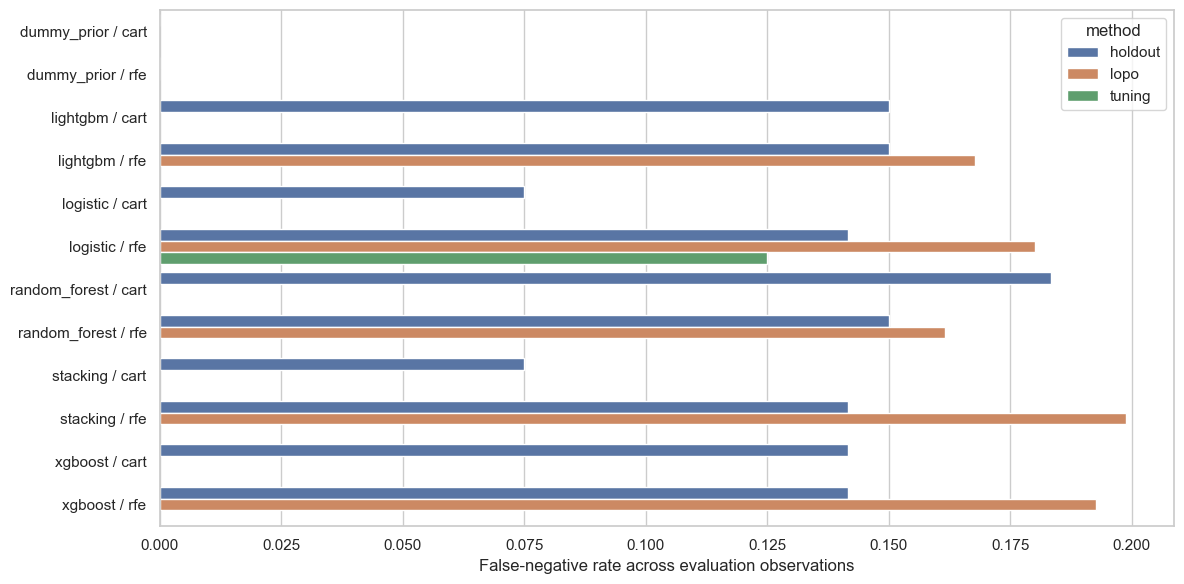

In [2]:
display(errors[["method", "seed", "model", "selection", "source_row", "error_type",
                "probability_present", "wrong_class_probability", "explanation"]].head(25))
display(errors.sort_values("threshold_distance")[["method", "model", "source_row",
                                                "error_type", "probability_present", "threshold_distance"]].head(20))
RESULTS = ROOT / "results" / "error_analysis"
plot_summary = summary.reset_index()
plot_summary["configuration"] = plot_summary.model + " / " + plot_summary.selection
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=plot_summary, x="fnr", y="configuration", hue="method", errorbar=None, ax=ax)
ax.set(xlabel="False-negative rate across evaluation observations", ylabel="")
fig.tight_layout()
fig.savefig(RESULTS / "false_negative_rates.png", dpi=150, bbox_inches="tight")
plt.show()


## 2. Continuous-feature profiles of errors

For one method/model/selector, compare original measurement medians for false negatives and correctly detected positive cases. Counts and missing comparison groups are retained; small groups can be unstable. This comparison does not explain causation or feature contributions to individual predictions.


In [3]:
X, y, manifest = require_exports()
PROFILE_METHOD = "holdout" if "holdout" in predictions.method.unique() else predictions.method.iloc[0]
PROFILE_MODEL = "logistic"
PROFILE_SELECTION = "rfe"
view = predictions.loc[(predictions.method == PROFILE_METHOD) &
                      (predictions.model == PROFILE_MODEL) &
                      (predictions.selection == PROFILE_SELECTION)].copy()
view["group"] = np.select([view.error_type.eq("FN"),
                           view.actual_present.eq(1) & view.predicted_present.eq(1)], ["FN", "TP"], default="Other")
view = view.join(X, on="source_row")
fields = continuous_columns(X)
profiles = view.loc[view.group.isin(["FN","TP"])].groupby("group")[fields].median().T
profiles.to_csv(RESULTS / "false_negative_feature_medians.csv", index_label="feature")
display(view.groupby("group").size().rename("evaluation_observations"))
display(profiles)


group
FN        17
Other    120
TP       103
Name: evaluation_observations, dtype: int64

group,FN,TP
age,48.00,47.00
height,163.00,170.00
weight,78.70,80.50
bmi,29.80,28.30
tbw,35.70,41.80
ecw,16.10,17.50
icw,18.10,23.90
ecf_tbw,45.00,42.00
tbfr_pct,32.10,26.10
lm_pct,67.92,73.91
